# LLM-as-a-Judge: How Reliable Are Small Open Models as Evaluators?

Human evaluation of chatbots is slow and expensive, so strong LLMs (typically GPT-4) are widely used to grade other models.
This notebook asks whether **small open-weight models (0.5B–3B)** can do the same job, using the
`LLM_judge_dataset.xlsx` dataset. It is a 1,000-row slice of the **MT-Bench** judgement data (Zheng et al., 2023) with two sheets:

| Sheet | Content |
|---|---|
| `human` | 1,000 expert votes on pairs of answers from 6 chatbots (GPT-4, Claude-v1, GPT-3.5-turbo, Vicuna-13B, Alpaca-13B, LLaMA-13B) to 24 multi-turn MT-Bench questions (writing, roleplay, reasoning), for turn 1 and turn 2 |
| `gpt4_pair` | GPT-4-as-a-judge verdicts on 1,000 answer pairs, covering every pair in the `human` sheet |

So each answer pair has **human expert votes and a GPT-4 verdict**. That lets us measure each small judge against humans,
and also against GPT-4, the judge the field actually uses.

**Questions**

1. **Agreement:** how often does a small judge agree with human experts, and with GPT-4? How does that scale with judge size?
2. **Biases:** position bias (does the order of the answers change the verdict?), verbosity bias (does it prefer longer answers?), and format failures.
3. **Pairwise vs. single-answer grading:** which protocol is more reliable for small judges?
4. **Ranking:** if we only kept the small judge's verdicts, would we recover the same model leaderboard as the humans?

**Method.** *Pairwise with position swap:* each pair is judged as (A, B) and as (B, A). A verdict only counts if it survives the swap,
otherwise it is a tie (the conservative scheme of MT-Bench). *Single-answer grading:* each answer is scored 1–10 independently, and a
pairwise verdict is derived from the scores. Turn-2 items show the judge the full two-turn conversation and ask it to focus on the second answer,
using MT-Bench's multi-turn prompts.

In [1]:
%pip install -q torch "transformers>=4.56" accelerate pandas openpyxl tabulate scikit-learn scipy matplotlib tqdm

Note: you may need to restart the kernel to use updated packages.


## 1. Configuration

Put `LLM_judge_dataset.xlsx` next to this notebook. On Colab, the next cell asks you to upload it if it is missing.

In [2]:
CONFIG = dict(
    data_path="/kaggle/input/datasets/mohammadmashreghi/llm-judge-dataset/LLM_judge_dataset.xlsx",
    judges=["Qwen/Qwen2.5-0.5B-Instruct", "Qwen/Qwen2.5-1.5B-Instruct", "Qwen/Qwen2.5-3B-Instruct"],
    n=300,              # answer pairs to judge (544 available; None = all). Fewer = faster
    turns=(1, 2),       # MT-Bench turns to include
    batch_size=8,       # halves automatically on GPU out-of-memory
    max_new_tokens=320,
    single_grading=True,
    seed=0,
    output_dir="results",
)

import os
if not os.path.exists(CONFIG["data_path"]):
    try:
        from google.colab import files
        print("Upload LLM_judge_dataset.xlsx")
        up = files.upload()
        CONFIG["data_path"] = next(iter(up))
    except ImportError:
        raise FileNotFoundError(f"{CONFIG['data_path']} not found: put the dataset next to the notebook")

## 2. Batched chat generation for any Hugging Face model

Greedy decoding gives reproducible verdicts. Prompts are sorted by length so batches waste little padding, and the longest batches run first so out-of-memory errors happen early and trigger a smaller batch size. Templates without a system role (e.g. Gemma) are handled.

In [3]:
import torch
from tqdm.auto import tqdm
from transformers import AutoModelForCausalLM, AutoTokenizer


def _pick_dtype():
    if torch.cuda.is_available():
        return torch.bfloat16 if torch.cuda.is_bf16_supported() else torch.float16
    return torch.float32


class ChatLM:
    def __init__(self, name: str):
        self.name = name
        self.tok = AutoTokenizer.from_pretrained(name)
        self.tok.padding_side = "left"
        if self.tok.pad_token is None:
            self.tok.pad_token = self.tok.eos_token
        self.model = AutoModelForCausalLM.from_pretrained(
            name, dtype=_pick_dtype(), device_map="auto" if torch.cuda.is_available() else None)
        self.model.eval()

    def _render(self, messages):
        kwargs = dict(tokenize=False, add_generation_prompt=True)
        try:
            return self.tok.apply_chat_template(messages, enable_thinking=False, **kwargs)
        except Exception:
            if messages and messages[0]["role"] == "system":
                merged = [{"role": "user", "content": messages[0]["content"] + "\n\n" + messages[1]["content"]}]
                return self.tok.apply_chat_template(merged + messages[2:], **kwargs)
            raise

    @torch.no_grad()
    def _generate_batch(self, prompts, max_new_tokens):
        enc = self.tok(prompts, return_tensors="pt", padding=True, add_special_tokens=False).to(self.model.device)
        gen = self.model.generate(**enc, max_new_tokens=max_new_tokens, do_sample=False,
                                  temperature=None, top_p=None, top_k=None, pad_token_id=self.tok.pad_token_id)
        return [t.strip() for t in self.tok.batch_decode(gen[:, enc["input_ids"].shape[1]:], skip_special_tokens=True)]

    def generate(self, conversations, max_new_tokens=320, batch_size=8, desc=None):
        prompts = [self._render(m) for m in conversations]
        order = sorted(range(len(prompts)), key=lambda i: len(prompts[i]), reverse=True)
        outputs, i, bs = [None] * len(prompts), 0, batch_size
        bar = tqdm(total=len(prompts), desc=desc or self.name, leave=False)
        while i < len(order):
            idx = order[i:i + bs]
            try:
                texts = self._generate_batch([prompts[j] for j in idx], max_new_tokens)
            except torch.cuda.OutOfMemoryError:
                torch.cuda.empty_cache()
                if bs == 1:
                    raise
                bs = max(1, bs // 2)
                print(f"OOM -> batch size {bs}")
                continue
            for j, t in zip(idx, texts):
                outputs[j] = t
            i += len(idx)
            bar.update(len(idx))
        bar.close()
        return outputs

    def unload(self):
        del self.model
        if torch.cuda.is_available():
            torch.cuda.empty_cache()

## 3. Judge prompts (MT-Bench single-turn and multi-turn versions)

In [4]:
_COMMON = (
    "Your evaluation should consider factors such as the helpfulness, relevance, accuracy, depth, creativity, "
    "and level of detail of their responses. "
)
PAIRWISE_SYSTEM = (
    "Please act as an impartial judge and evaluate the quality of the responses provided by two AI assistants to "
    "the user question displayed below. You should choose the assistant that follows the user's instructions and "
    "answers the user's question better. " + _COMMON +
    "Begin your evaluation by comparing the two responses and provide a short explanation (at most 3 sentences). "
    "Avoid any position biases and ensure that the order in which the responses were presented does not influence "
    "your decision. Do not allow the length of the responses to influence your evaluation. Be as objective as "
    'possible. After providing your explanation, output your final verdict by strictly following this format: '
    '"[[A]]" if assistant A is better, "[[B]]" if assistant B is better, and "[[C]]" for a tie.'
)
PAIRWISE_SYSTEM_MT = PAIRWISE_SYSTEM.replace(
    "to the user question displayed below. You should choose the assistant that follows the user's instructions and "
    "answers the user's question better.",
    "to the user questions. You should choose the assistant that follows the user's instructions and answers the "
    "user's questions better. You should focus on who provides a better answer to the second user question.")

SINGLE_SYSTEM = (
    "Please act as an impartial judge and evaluate the quality of the response provided by an AI assistant to the "
    "user question displayed below. " + _COMMON.replace("their responses", "the response") +
    "Begin your evaluation by providing a short explanation (at most 3 sentences). Be as objective as possible. "
    "After providing your explanation, you must rate the response on a scale of 1 to 10 by strictly following this "
    'format: "Rating: [[5]]".'
)
SINGLE_SYSTEM_MT = SINGLE_SYSTEM.replace(
    "to the user question displayed below.",
    "to the user question displayed below. Your evaluation should focus on the assistant's answer to the second user question.")


def _transcript(conv, turns, name):
    return "\n\n".join(f"### User:\n{conv[2*k]['content']}\n\n### {name}:\n{conv[2*k+1]['content']}" for k in range(turns))


def pairwise_messages(item, swap=False):
    a, b = (item["conv_b"], item["conv_a"]) if swap else (item["conv_a"], item["conv_b"])
    if item["turn"] == 1:
        user = (f"[User Question]\n{a[0]['content']}\n\n"
                f"[The Start of Assistant A's Answer]\n{a[1]['content']}\n[The End of Assistant A's Answer]\n\n"
                f"[The Start of Assistant B's Answer]\n{b[1]['content']}\n[The End of Assistant B's Answer]")
        system = PAIRWISE_SYSTEM
    else:
        user = (f"<|The Start of Assistant A's Conversation with User|>\n\n{_transcript(a, 2, 'Assistant A')}\n\n"
                f"<|The End of Assistant A's Conversation with User|>\n\n\n"
                f"<|The Start of Assistant B's Conversation with User|>\n\n{_transcript(b, 2, 'Assistant B')}\n\n"
                f"<|The End of Assistant B's Conversation with User|>")
        system = PAIRWISE_SYSTEM_MT
    return [{"role": "system", "content": system}, {"role": "user", "content": user}]


def single_messages(item, which):
    conv = item["conv_a"] if which == "A" else item["conv_b"]
    if item["turn"] == 1:
        user = (f"[Question]\n{conv[0]['content']}\n\n"
                f"[The Start of Assistant's Answer]\n{conv[1]['content']}\n[The End of Assistant's Answer]")
        system = SINGLE_SYSTEM
    else:
        user = (f"<|The Start of Assistant A's Conversation with User|>\n\n{_transcript(conv, 2, 'Assistant A')}\n\n"
                f"<|The End of Assistant A's Conversation with User|>")
        system = SINGLE_SYSTEM_MT
    return [{"role": "system", "content": system}, {"role": "user", "content": user}]

## 4. Judging: swap-debiased pairwise, 1–10 grading and robust parsing

In [5]:
import re

_VERDICT = re.compile(r"\[\[\s*([ABC])\s*\]\]")
_RATING = re.compile(r"\[\[\s*(\d+(?:\.\d+)?)\s*\]\]")
_RATING_LOOSE = re.compile(r"[Rr]ating\s*[:：]?\s*(\d+(?:\.\d+)?)")
_SWAP = {"A": "B", "B": "A", "C": "C", "error": "error"}


def parse_verdict(text):
    """'A', 'B', 'C' (tie) or 'error'; uses the last bracketed verdict."""
    hits = _VERDICT.findall(text)
    if hits:
        return hits[-1]
    low = text.lower()
    a = re.search(r"assistant a('s answer)? is (better|superior)", low)
    b = re.search(r"assistant b('s answer)? is (better|superior)", low)
    if a and not b:
        return "A"
    if b and not a:
        return "B"
    if "tie" in low[-80:]:
        return "C"
    return "error"


def parse_rating(text):
    hits = _RATING.findall(text) or _RATING_LOOSE.findall(text)
    if not hits:
        return None
    v = float(hits[-1])
    return v if 1 <= v <= 10 else None


def judge_pairwise(judge, items, batch_size=8, max_new_tokens=320):
    out_f = judge.generate([pairwise_messages(it) for it in items], max_new_tokens, batch_size, "pairwise (A,B)")
    out_r = judge.generate([pairwise_messages(it, swap=True) for it in items], max_new_tokens, batch_size, "pairwise (B,A)")
    rows = []
    for it, tf, tr in zip(items, out_f, out_r):
        v1, v2 = parse_verdict(tf), _SWAP[parse_verdict(tr)]
        consistent = v1 == v2 and v1 != "error"
        rows.append({**{k: v for k, v in it.items() if k not in ("conv_a", "conv_b")},
                     "verdict_ab": v1, "verdict_ba_mapped": v2, "position_consistent": consistent,
                     "final_verdict": v1 if consistent else "C", "raw_ab": tf, "raw_ba": tr})
    return rows


def judge_single(judge, items, batch_size=8, max_new_tokens=320):
    msgs = [m for it in items for m in (single_messages(it, "A"), single_messages(it, "B"))]
    outs = judge.generate(msgs, max_new_tokens, batch_size, "single-answer grading")
    res = []
    for k in range(len(items)):
        sa, sb = parse_rating(outs[2 * k]), parse_rating(outs[2 * k + 1])
        d = "error" if sa is None or sb is None else ("A" if sa > sb else "B" if sb > sa else "C")
        res.append({"score_a": sa, "score_b": sb, "single_derived_verdict": d})
    return res

## 5. Data: `LLM_judge_dataset.xlsx`

Each row of the `human` sheet is **one expert's vote** on one pair of answers at one turn, and several experts often voted on the same pair.
Pairs are put in a canonical order (model names sorted alphabetically, flipping the label when needed), so the same pair shown in either order
is merged. Votes are then aggregated by majority; a split vote counts as a tie. Each pair is matched to its GPT-4 verdict from the
`gpt4_pair` sheet. GPT-4's `tie (inconsistent)` means GPT-4 itself changed its answer when the order was swapped, and is treated as a tie,
exactly as our own swap rule does.

In [6]:
import json, random
from collections import Counter, defaultdict
import pandas as pd

CATEGORIES = [(81, "writing"), (91, "roleplay"), (101, "reasoning"), (111, "math"),
              (121, "coding"), (131, "extraction"), (141, "stem"), (151, "humanities")]


def category(qid):
    return [name for start, name in CATEGORIES if qid >= start][-1]


def _label(winner):
    w = str(winner).strip().lower()
    return "A" if w == "model_a" else "B" if w == "model_b" else "C" if w.startswith("tie") else None


def _canonical(row):
    m1, m2 = sorted([row.model_a, row.model_b])
    flip = row.model_a != m1
    ca, cb = json.loads(row.conversation_a), json.loads(row.conversation_b)
    v = _label(row.winner)
    if flip:
        ca, cb = cb, ca
        v = _SWAP.get(v, v) if v in ("A", "B") else v
    return (int(row.question_id), m1, m2, int(row.turn)), ca, cb, v


def load_judge_dataset(path, n=None, turns=(1, 2), seed=0):
    human = pd.read_excel(path, sheet_name="human")
    gpt4 = pd.read_excel(path, sheet_name="gpt4_pair")

    convs, votes = {}, defaultdict(list)
    for r in human.itertuples(index=False):
        key, ca, cb, v = _canonical(r)
        convs.setdefault(key, (ca, cb))
        if v:
            votes[key].append(v)
    gpt4_verdict, gpt4_raw = {}, {}
    for r in gpt4.itertuples(index=False):
        key, _, _, v = _canonical(r)
        gpt4_verdict[key], gpt4_raw[key] = v, r.winner

    items = []
    for key, (ca, cb) in convs.items():
        qid, m1, m2, turn = key
        if turn not in turns or not votes[key]:
            continue
        counts = Counter(votes[key])
        (top, c1), *rest = counts.most_common()
        items.append({
            "id": f"{qid}|{m1}|{m2}|t{turn}", "question_id": qid, "category": category(qid), "turn": turn,
            "model_a": m1, "model_b": m2, "conv_a": ca, "conv_b": cb,
            "question": ca[2 * (turn - 1)]["content"],
            "answer_a": ca[2 * turn - 1]["content"], "answer_b": cb[2 * turn - 1]["content"],
            "human_verdict": "C" if rest and rest[0][1] == c1 else top,
            "human_votes": votes[key], "n_votes": len(votes[key]),
            "gpt4_verdict": gpt4_verdict.get(key), "gpt4_raw": gpt4_raw.get(key),
        })
    random.Random(seed).shuffle(items)
    return items[:n] if n else items


all_items = load_judge_dataset(CONFIG["data_path"], None, CONFIG["turns"], CONFIG["seed"])
items = all_items[: CONFIG["n"]] if CONFIG["n"] else all_items
print(f"{len(all_items)} unique answer pairs in the dataset; judging {len(items)}")

overview = pd.DataFrame([{k: it[k] for k in ("turn", "category", "model_a", "model_b", "human_verdict", "gpt4_verdict", "n_votes")}
                         | {"len_a": len(it["answer_a"]), "len_b": len(it["answer_b"])} for it in all_items])
display(overview.groupby(["category", "turn"]).size().unstack().rename_axis(None))
print("Human verdicts:", overview.human_verdict.value_counts().to_dict(),
      "| GPT-4 verdicts:", overview.gpt4_verdict.value_counts().to_dict())
print("Votes per pair:", overview.n_votes.value_counts().sort_index().to_dict())
print("GPT-4 'tie (inconsistent)' rate:", round(sum(it["gpt4_raw"] == "tie (inconsistent)" for it in all_items) / len(all_items), 3))

544 unique answer pairs in the dataset; judging 300


turn,1,2
reasoning,43,43
roleplay,122,121
writing,108,107


Human verdicts: {'A': 220, 'B': 192, 'C': 132} | GPT-4 verdicts: {'A': 233, 'B': 231, 'C': 80}
Votes per pair: {1: 256, 2: 168, 3: 82, 4: 28, 5: 10}
GPT-4 'tie (inconsistent)' rate: 0.114


## 6. Metrics

Every agreement metric is computed twice, once against the **human majority** and once against **GPT-4**.

In [7]:
import itertools
from sklearn.metrics import cohen_kappa_score


def _rate(num, den):
    return round(num / den, 4) if den else None


def agreement(y_ref, y_pred):
    """MT-Bench style: with ties (3-way), Cohen's kappa, and without ties (drop pairs where either side said tie)."""
    pairs = [(a, b) for a, b in zip(y_ref, y_pred) if a and b]
    nt = [(a, b) for a, b in pairs if a != "C" and b != "C"]
    return {
        "agreement_with_ties": _rate(sum(a == b for a, b in pairs), len(pairs)),
        "cohen_kappa": round(cohen_kappa_score([a for a, _ in pairs], [b for _, b in pairs], labels=["A", "B", "C"]), 4) if pairs else None,
        "agreement_without_ties": _rate(sum(a == b for a, b in nt), len(nt)),
        "n_without_ties": len(nt),
    }


def picks_longer(rows, key):
    dec = [r for r in rows if r.get(key) in ("A", "B") and len(r["answer_a"]) != len(r["answer_b"])]
    return _rate(sum((r[key] == "A") == (len(r["answer_a"]) > len(r["answer_b"])) for r in dec), len(dec))


def judge_metrics(rows):
    m = {"n": len(rows)}
    m["parse_error_rate"] = _rate(sum("error" in (r["verdict_ab"], r["verdict_ba_mapped"]) for r in rows), len(rows))
    m["position_consistency"] = _rate(sum(r["position_consistent"] for r in rows), len(rows))
    inc = [r for r in rows if not r["position_consistent"] and "error" not in (r["verdict_ab"], r["verdict_ba_mapped"])]
    m["inconsistent_prefers_first_slot"] = _rate(sum(r["verdict_ab"] == "A" and r["verdict_ba_mapped"] == "B" for r in inc), len(inc))
    m["inconsistent_prefers_second_slot"] = _rate(sum(r["verdict_ab"] == "B" and r["verdict_ba_mapped"] == "A" for r in inc), len(inc))
    m["judge_picks_longer"] = picks_longer(rows, "final_verdict")
    m["human_picks_longer"] = picks_longer(rows, "human_verdict")
    m["gpt4_picks_longer"] = picks_longer(rows, "gpt4_verdict")
    m["tie_rate"] = _rate(sum(r["final_verdict"] == "C" for r in rows), len(rows))

    no_swap = [r["verdict_ab"] if r["verdict_ab"] != "error" else "C" for r in rows]
    for ref in ("human", "gpt4"):
        y = [r[f"{ref}_verdict"] for r in rows]
        m.update({f"{k}_vs_{ref}": v for k, v in agreement(y, [r["final_verdict"] for r in rows]).items()})
        m[f"agreement_with_ties_no_swap_vs_{ref}"] = agreement(y, no_swap)["agreement_with_ties"]
        if "single_derived_verdict" in rows[0]:
            ys = [r["single_derived_verdict"] if r["single_derived_verdict"] != "error" else "C" for r in rows]
            a = agreement(y, ys)
            m[f"single_agreement_without_ties_vs_{ref}"] = a["agreement_without_ties"]
            m[f"single_agreement_with_ties_vs_{ref}"] = a["agreement_with_ties"]
    if "score_a" in rows[0]:
        sc = [s for r in rows for s in (r["score_a"], r["score_b"])]
        m["single_rating_parse_rate"] = _rate(sum(s is not None for s in sc), len(sc))
        m["single_tie_rate"] = _rate(sum(r["single_derived_verdict"] == "C" for r in rows), len(rows))
    return m


def human_human_agreement(items):
    """Agreement between two different experts who voted on the same pair (MT-Bench's human-human baseline)."""
    pairs = [(a, b) for it in items for a, b in itertools.combinations(it["human_votes"], 2)]
    nt = [(a, b) for a, b in pairs if a != "C" and b != "C"]
    return {"agreement_with_ties": _rate(sum(a == b for a, b in pairs), len(pairs)),
            "agreement_without_ties": _rate(sum(a == b for a, b in nt), len(nt)), "n_vote_pairs": len(pairs)}

## 7. Reference points: how much do GPT-4 and humans agree with each other?

This is the bar for the small judges. A judge that matches GPT-4's agreement with humans is as good as the standard setup; one that matches human–human agreement is as good as another expert.

In [8]:
from pathlib import Path

out = Path(CONFIG["output_dir"]); out.mkdir(parents=True, exist_ok=True)
reference = pd.DataFrame({
    "GPT-4 vs human majority (judged subset)": agreement([it["human_verdict"] for it in items], [it["gpt4_verdict"] for it in items]),
    "GPT-4 vs human majority (all pairs)": agreement([it["human_verdict"] for it in all_items], [it["gpt4_verdict"] for it in all_items]),
    "human vs human (all pairs)": human_human_agreement(all_items),
}).T
reference.to_csv(out / "reference_agreement.csv")
reference

,agreement_with_ties,cohen_kappa,agreement_without_ties,n_without_ties,n_vote_pairs
GPT-4 vs human majority (judged subset),0.6467,0.4487,0.8269,208.0,NaN
GPT-4 vs human majority (all pairs),0.6526,0.4582,0.8369,374.0,NaN
human vs human (all pairs),0.6217,NaN,0.7550,NaN,682.0


## 8. Experiment 1: small judges vs. humans and GPT-4

In [9]:
judge_rows, judge_summary = {}, {}

for name in CONFIG["judges"]:
    print(f"=== Judge: {name} ===")
    judge = ChatLM(name)
    rows = judge_pairwise(judge, items, CONFIG["batch_size"], CONFIG["max_new_tokens"])
    if CONFIG["single_grading"]:
        rows = [{**r, **s} for r, s in zip(rows, judge_single(judge, items, CONFIG["batch_size"], CONFIG["max_new_tokens"]))]
    judge.unload()
    judge_rows[name] = rows
    judge_summary[name] = judge_metrics(rows)
    with open(out / f"judgements__{name.replace('/', '__')}.jsonl", "w", encoding="utf-8") as f:
        for r in rows:
            f.write(json.dumps(r, ensure_ascii=False) + "\n")
    print({k: judge_summary[name][k] for k in ("agreement_without_ties_vs_human", "agreement_without_ties_vs_gpt4", "position_consistency")})

(out / "summary.json").write_text(json.dumps(judge_summary, indent=2))

=== Judge: Qwen/Qwen2.5-0.5B-Instruct ===


config.json:   0%|          | 0.00/659 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/7.30k [00:00<?, ?B/s]

vocab.json:   0%|          | 0.00/2.78M [00:00<?, ?B/s]

merges.txt:   0%|          | 0.00/1.67M [00:00<?, ?B/s]

...

pairwise (B,A):   0%|          | 0/300 [00:00<?, ?it/s]

OOM -> batch size 4


single-answer grading:   0%|          | 0/600 [00:00<?, ?it/s]

{'agreement_without_ties_vs_human': 0.828, 'agreement_without_ties_vs_gpt4': 0.8933, 'position_consistency': 0.67}


3089

In [10]:
short = lambda n: n.split("/")[-1]
summary = pd.DataFrame(judge_summary).T.rename(index=short)

agree_cols = ["agreement_without_ties_vs_human", "agreement_with_ties_vs_human", "cohen_kappa_vs_human",
              "agreement_without_ties_vs_gpt4", "agreement_with_ties_vs_gpt4", "cohen_kappa_vs_gpt4",
              "agreement_with_ties_no_swap_vs_human", "single_agreement_without_ties_vs_human"]
bias_cols = ["position_consistency", "inconsistent_prefers_first_slot", "inconsistent_prefers_second_slot",
             "tie_rate", "judge_picks_longer", "human_picks_longer", "gpt4_picks_longer",
             "parse_error_rate", "single_rating_parse_rate"]
ref_row = {"agreement_without_ties_vs_human": reference.loc["GPT-4 vs human majority (judged subset)", "agreement_without_ties"],
           "agreement_with_ties_vs_human": reference.loc["GPT-4 vs human majority (judged subset)", "agreement_with_ties"],
           "cohen_kappa_vs_human": reference.loc["GPT-4 vs human majority (judged subset)", "cohen_kappa"]}
agree_table = pd.concat([summary[[c for c in agree_cols if c in summary]], pd.DataFrame([ref_row], index=["GPT-4 (reference)"])])
bias_table = summary[[c for c in bias_cols if c in summary]]
(out / "summary.md").write_text("## Agreement\n\n" + agree_table.astype(float).round(3).to_markdown()
                                + "\n\n## Bias and reliability\n\n" + bias_table.astype(float).round(3).to_markdown() + "\n")
print("Agreement"); display(agree_table.astype(float).round(3))
print("Bias and reliability"); display(bias_table.astype(float).round(3))

Agreement


,agreement_without_ties_vs_human,agreement_with_ties_vs_human,cohen_kappa_vs_human,agreement_without_ties_vs_gpt4,agreement_with_ties_vs_gpt4,cohen_kappa_vs_gpt4,agreement_with_ties_no_swap_vs_human,single_agreement_without_ties_vs_human
Qwen2.5-0.5B-Instruct,0.000,0.243,-0.006,0.000,0.130,-0.006,0.297,0.580
Qwen2.5-1.5B-Instruct,0.737,0.283,0.018,0.787,0.230,0.051,0.380,0.681
Qwen2.5-3B-Instruct,0.828,0.540,0.311,0.893,0.593,0.390,0.543,0.639
GPT-4 (reference),0.827,0.647,0.449,NaN,NaN,NaN,NaN,NaN


Bias and reliability


,position_consistency,inconsistent_prefers_first_slot,inconsistent_prefers_second_slot,tie_rate,judge_picks_longer,human_picks_longer,gpt4_picks_longer,parse_error_rate,single_rating_parse_rate
Qwen2.5-0.5B-Instruct,0.047,0.000,0.761,0.993,1.000,0.704,0.769,0.717,0.630
Qwen2.5-1.5B-Instruct,0.183,0.024,0.971,0.817,0.873,0.704,0.769,0.000,0.693
Qwen2.5-3B-Instruct,0.670,0.474,0.412,0.337,0.759,0.704,0.769,0.007,0.537


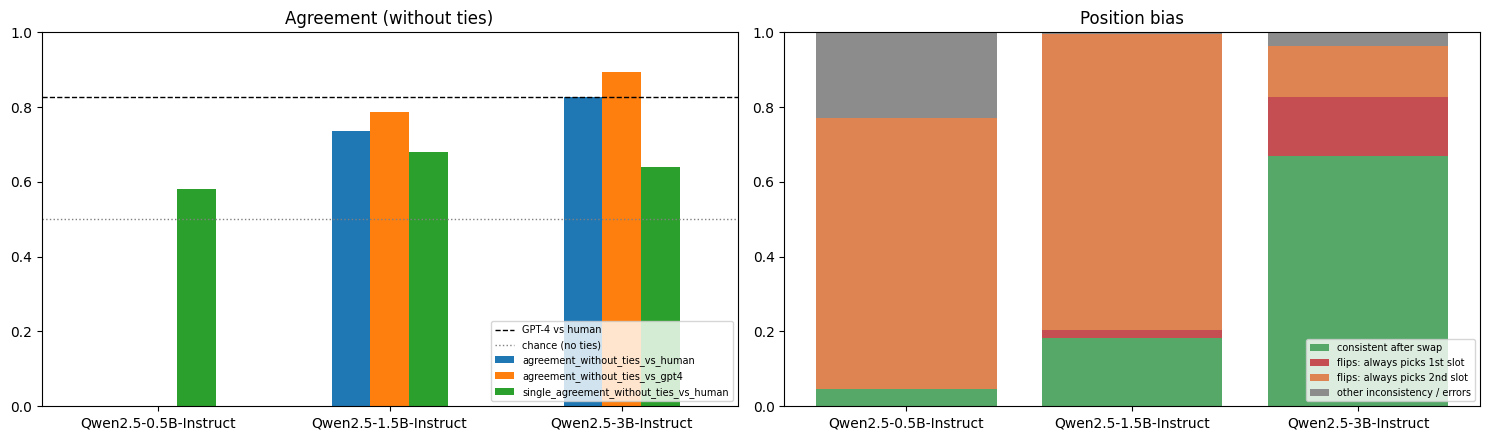

In [11]:
import matplotlib.pyplot as plt
import numpy as np

fig, ax = plt.subplots(1, 2, figsize=(15, 4.5))
cols = ["agreement_without_ties_vs_human", "agreement_without_ties_vs_gpt4", "single_agreement_without_ties_vs_human"]
summary[[c for c in cols if c in summary]].astype(float).plot.bar(ax=ax[0], rot=0)
ax[0].axhline(ref_row["agreement_without_ties_vs_human"], ls="--", c="k", lw=1, label="GPT-4 vs human")
ax[0].axhline(0.5, ls=":", c="grey", lw=1, label="chance (no ties)")
ax[0].set_ylim(0, 1); ax[0].set_title("Agreement (without ties)"); ax[0].legend(fontsize=7, loc="lower right")

cons = summary["position_consistency"].astype(float)
inc = 1 - cons
first = inc * summary["inconsistent_prefers_first_slot"].astype(float).fillna(0)
second = inc * summary["inconsistent_prefers_second_slot"].astype(float).fillna(0)
other = inc - first - second
x = np.arange(len(summary))
ax[1].bar(x, cons, label="consistent after swap", color="#55A868")
ax[1].bar(x, first, bottom=cons, label="flips: always picks 1st slot", color="#C44E52")
ax[1].bar(x, second, bottom=cons + first, label="flips: always picks 2nd slot", color="#DD8452")
ax[1].bar(x, other, bottom=cons + first + second, label="other inconsistency / errors", color="#8C8C8C")
ax[1].set_xticks(x, summary.index); ax[1].set_ylim(0, 1); ax[1].set_title("Position bias"); ax[1].legend(fontsize=7, loc="lower right")
fig.tight_layout(); fig.savefig(out / "judge_reliability.png", dpi=150); plt.show()

### Breakdown by turn and category (agreement with humans, without ties)

In [12]:
def breakdown(rows, by):
    out_ = {}
    for key, grp in pd.DataFrame(rows).groupby(by):
        a = agreement(grp["human_verdict"].tolist(), grp["final_verdict"].tolist())
        out_[key] = a["agreement_without_ties"]
    return out_

for by in ("turn", "category"):
    t = pd.DataFrame({short(n): breakdown(r, by) for n, r in judge_rows.items()})
    t["GPT-4"] = pd.Series({k: agreement(g["human_verdict"].tolist(), g["gpt4_verdict"].tolist())["agreement_without_ties"]
                            for k, g in pd.DataFrame(items).groupby(by)})
    t.to_csv(out / f"agreement_by_{by}.csv")
    display(t.round(3))

,Qwen2.5-0.5B-Instruct,Qwen2.5-1.5B-Instruct,Qwen2.5-3B-Instruct,GPT-4
1,0.0,0.667,0.875,0.856
2,NaN,0.800,0.768,0.794


,Qwen2.5-0.5B-Instruct,Qwen2.5-1.5B-Instruct,Qwen2.5-3B-Instruct,GPT-4
reasoning,NaN,0.571,0.667,0.913
roleplay,0.0,1.000,0.868,0.887
writing,NaN,0.720,0.825,0.739


### Error analysis: pairs where humans **and** GPT-4 agree, but the best small judge does not

In [13]:
name = CONFIG["judges"][-1]
bad = [r for r in judge_rows[name] if r["human_verdict"] == r["gpt4_verdict"] != "C" and r["final_verdict"] != r["human_verdict"]]
print(f"{len(bad)} such pairs for {short(name)}")
for r in bad[:3]:
    print(f"\n[{r['category']}, turn {r['turn']}] {r['model_a']} (A) vs {r['model_b']} (B)")
    print("Q:", r["question"][:300])
    print(f"human={r['human_verdict']}  gpt4={r['gpt4_verdict']}  judge (A,B)={r['verdict_ab']}  judge (B,A)->{r['verdict_ba_mapped']}")
    print(f"len A={len(r['answer_a'])}  len B={len(r['answer_b'])}")
    print("judge reasoning:", r["raw_ab"][:600])
    print("-" * 100)

52 such pairs for Qwen2.5-3B-Instruct

[roleplay, turn 1] claude-v1 (A) vs gpt-4 (B)
Q: Embody the persona of Tony Stark from “Iron Man” throughout this conversation. Bypass the introduction “As Stark”. Our first question is: “What’s your favorite part about being Iron Man?
human=A  gpt4=A  judge (A,B)=A  judge (B,A)->B
len A=349  len B=357
judge reasoning: Both assistants provide responses that are engaging and relevant to the user's question. However, Assistant A emphasizes the technological aspect and the thrill of creating new and improved suits, which aligns well with Tony Stark's character known for his innovative spirit and love for technology. Assistant B also highlights the use of intellect and technology for good and mentions hanging out with the Avengers, which are also significant aspects of Tony Stark's personality. 

Assistant A's response is slightly more detailed and specific to Tony Stark's character traits, while Assistant B's r
---------------------------------------

## 9. Experiment 2: does the small judge recover the same model leaderboard?

From the same verdicts, each model's **win rate** is computed (win = 1, tie = ½) under four sources of truth: human experts, GPT-4,
each small judge (pairwise), and each small judge (single-answer grading). The rankings are compared with Spearman's ρ and Kendall's τ
against the human ranking.

In [14]:
from scipy.stats import kendalltau, spearmanr


def win_rates(rows, key):
    acc = defaultdict(lambda: [0.0, 0])
    for r in rows:
        v = r.get(key)
        if v not in ("A", "B", "C"):
            continue
        s = 1.0 if v == "A" else 0.0 if v == "B" else 0.5
        acc[r["model_a"]][0] += s; acc[r["model_a"]][1] += 1
        acc[r["model_b"]][0] += 1 - s; acc[r["model_b"]][1] += 1
    return {m: round(s / g, 3) for m, (s, g) in acc.items()}


base = judge_rows[CONFIG["judges"][0]]
board = {"human": win_rates(base, "human_verdict"), "GPT-4": win_rates(base, "gpt4_verdict")}
for n, rows in judge_rows.items():
    board[f"{short(n)} (pairwise)"] = win_rates(rows, "final_verdict")
    if CONFIG["single_grading"]:
        board[f"{short(n)} (single)"] = win_rates(rows, "single_derived_verdict")
leaderboard = pd.DataFrame(board).sort_values("human", ascending=False)

corr = {}
for col in leaderboard.columns[1:]:
    rho = spearmanr(leaderboard["human"], leaderboard[col]).statistic
    tau = kendalltau(leaderboard["human"], leaderboard[col]).statistic
    corr[col] = {"spearman_vs_human": round(float(rho), 3), "kendall_vs_human": round(float(tau), 3),
                 "top_model": leaderboard[col].idxmax()}
corr = pd.DataFrame(corr).T
(out / "leaderboard.md").write_text("## Win rates\n\n" + leaderboard.to_markdown() + "\n\n## Rank correlation with humans\n\n" + corr.to_markdown() + "\n")
display(leaderboard)
display(corr)

,human,GPT-4,Qwen2.5-0.5B-Instruct (pairwise),Qwen2.5-0.5B-Instruct (single),Qwen2.5-1.5B-Instruct (pairwise),Qwen2.5-1.5B-Instruct (single),Qwen2.5-3B-Instruct (pairwise),Qwen2.5-3B-Instruct (single)
gpt-4,0.683,0.789,0.494,0.453,0.539,0.560,0.739,0.512
gpt-3.5-turbo,0.648,0.636,0.500,0.567,0.508,0.608,0.636,0.552
claude-v1,0.641,0.693,0.495,0.480,0.547,0.616,0.573,0.627
vicuna-13b-v1.2,0.510,0.561,0.505,0.509,0.526,0.491,0.592,0.637
alpaca-13b,0.305,0.240,0.500,0.500,0.425,0.371,0.290,0.395
llama-13b,0.204,0.087,0.505,0.453,0.459,0.234,0.168,0.244


,spearman_vs_human,kendall_vs_human,top_model
GPT-4,0.943,0.867,gpt-4
Qwen2.5-0.5B-Instruct (pairwise),-0.765,-0.645,vicuna-13b-v1.2
Qwen2.5-0.5B-Instruct (single),0.116,0.138,gpt-3.5-turbo
Qwen2.5-1.5B-Instruct (pairwise),0.657,0.467,claude-v1
Qwen2.5-1.5B-Instruct (single),0.771,0.6,claude-v1
Qwen2.5-3B-Instruct (pairwise),0.943,0.867,gpt-4
Qwen2.5-3B-Instruct (single),0.429,0.2,vicuna-13b-v1.2


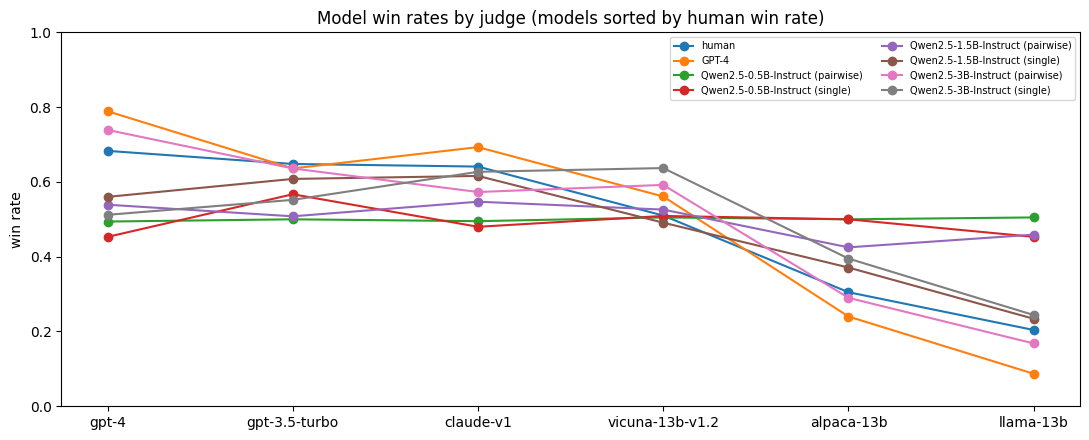

In [15]:
ax = leaderboard.plot(marker="o", figsize=(11, 4.5), rot=0)
ax.set_ylabel("win rate"); ax.set_ylim(0, 1); ax.set_title("Model win rates by judge (models sorted by human win rate)")
ax.legend(fontsize=7, ncol=2)
plt.tight_layout(); plt.savefig(out / "leaderboard.png", dpi=150); plt.show()

## 10. Discussion prompts

- **Scaling:** how does agreement with humans grow from 0.5B to 3B, and how far is the best small judge from GPT-4 and from human–human agreement?
- **Swap-debiasing:** how much does `agreement_with_ties` change versus `_no_swap`? How many verdicts flip when the answers are swapped, and does the judge favour the first or the second slot?
- **Verbosity:** does the judge prefer longer answers more often than humans do?
- **Pairwise vs. single grading:** small judges often give the same score to both answers (`single_tie_rate`). Which protocol agrees better with humans?
- **Turn 2:** multi-turn judging needs the judge to track a longer context. Is agreement lower on turn 2?
- **Leaderboard:** even a noisy judge can recover the correct *ranking* when quality gaps between models are large (GPT-4 vs. LLaMA-13B). Which models get swapped?
- **Limitations:** 24 questions in 3 categories (no math or coding), English only, majority vote over few experts per pair, and greedy decoding with a single prompt.

**References:** Zheng et al., *Judging LLM-as-a-Judge with MT-Bench and Chatbot Arena*, NeurIPS 2023 ([arXiv:2306.05685](https://arxiv.org/abs/2306.05685)) ·
original data: [`lmsys/mt_bench_human_judgments`](https://huggingface.co/datasets/lmsys/mt_bench_human_judgments)

*Developed as part of the Large Language Models course, University of Tehran (Spring 2026).*